[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/main/notebooks/learn/00_quickstart.ipynb)

In [1]:
# Colab setup. Does nothing when this notebook runs from a TorchLens checkout
# (learn_models.py is beside it). On Colab there is no checkout, so this installs
# TorchLens from the main branch and fetches learn_models.py next to the notebook.
import pathlib
import shutil
import subprocess
import sys
import urllib.request

if not pathlib.Path("learn_models.py").exists():
    REPO = "johnmarktaylor91/torchlens"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"torchlens[viz] @ git+https://github.com/{REPO}@main",
            "transformers",
            "ipywidgets",
        ],
        check=True,
    )
    if shutil.which("dot") is None:  # drawings need the Graphviz binary
        subprocess.run(["apt-get", "install", "-qq", "-y", "graphviz"], check=True)
    urllib.request.urlretrieve(
        f"https://raw.githubusercontent.com/{REPO}/main/notebooks/learn/learn_models.py",
        "learn_models.py",
    )

# TorchLens in five minutes

**Level 0 to 2 of 5. Starting point: you have a PyTorch model and want to see what happens inside it.**

TorchLens is one verb and one noun. The verb is `tl.trace(model, x)`: run the model once and
record everything. The noun is the `Trace` it returns, which you read like a dict. Activations,
metadata, a drawing, a summary, an edit and a gradient all fall out of that one object. Eight short steps below show the whole core; every later notebook is one of these steps with more
vocabulary.

> **You'll want to know:** how to build an `nn.Module` and call it on a tensor. That is all.

In [2]:
import tempfile
from pathlib import Path

import torch

import torchlens as tl

PICTURES = Path(
    tempfile.mkdtemp(prefix="torchlens_learn_")
)  # drawings land here, not beside the notebook

In [3]:
from learn_models import tiny_cnn, tiny_mlp  # tiny seeded CPU models; nothing downloads

model, x = tiny_mlp()  # two linear layers with a ReLU between them, and a (4, 8) input batch

## 1. Trace a model

One call runs the forward pass and records every operation. The summary is the first thing to
look at: one row per layer, with shapes, parameters and compute. That is the whole setup.

In [4]:
trace = tl.trace(model, x)
trace.summary()

name (type),output,params,(%),fwd flops
in_proj (Linear),"(4, 16)",144,67.9%,1.1k
relu_1,"(4, 16)",-,-,64
out_proj (Linear),"(4, 4)",68,32.1%,528


## 2. Read it like a dict

Every operation has an address. `relu_1_2` means: a `relu`, the first relu in the model, the
second operation overall. You can also ask by position, by any unique substring, and through
`trace.ops` by a module name (which gives you that module's output). Each record carries its activation and its metadata,
and knows its neighbours.

In [5]:
three_ways = [trace["relu_1_2"], trace[2], trace["relu"]]
print("same op three ways:", [op.layer_label for op in three_ways])
head = trace.ops["out_proj"]  # .ops turns a module name into its output op
print(
    "module output     :",
    head.layer_label,
    "| its module:",
    head.module,
    "| function:",
    head.func_name,
)

relu = trace["relu_1_2"]
print("shape", tuple(relu.shape), "| parents", relu.parents, "| children", relu.children)
relu.out[0, :6].detach()  # the activation itself: first item in the batch, first six units

same op three ways: ['relu_1_2', 'relu_1_2', 'relu_1_2']
module output     : linear_2_3 | its module: out_proj:1 | function: linear
shape (4, 16) | parents ('linear_1_1',) | children ('linear_2_3',)


tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0436, 0.0000])

## 3. Draw it

The same trace draws itself. When a model has too many boxes to read, `collapse=` folds whole
modules into fewer nodes: `"auto"` decides from the picture's size, `"max"` folds as far as it
can. Identical repeated blocks become one summary node; a block that differs from its siblings
(here the last one, whose output feeds the head) keeps its detail. The other dials, a module
focus, a rolled loop, colour and size as data, are in [03, See it](03_see_it.ipynb). The `Drawing` repr counts every record it drew, the input, output and BatchNorm buffer records included, so its `ops=` is larger than `len(trace.ops)`.


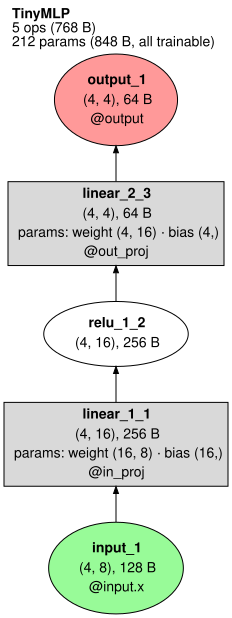

In [6]:
trace.draw(path=str(PICTURES / "mlp"), file_format="svg")

23 ops; collapse='max' folds the five identical blocks into one node.


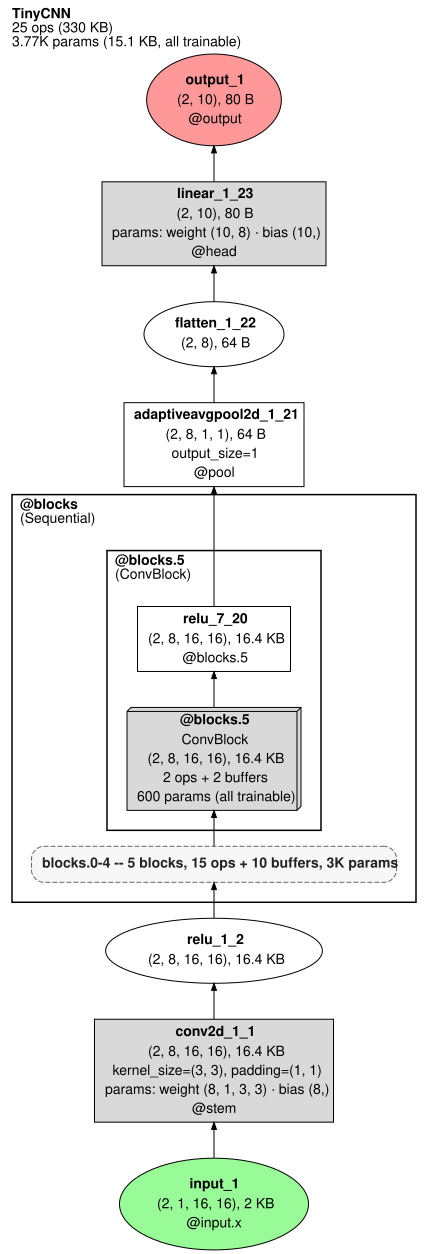

In [7]:
cnn, image = tiny_cnn()  # six conv blocks, each conv, BatchNorm, ReLU
big = tl.trace(cnn, image)
print(len(big.ops), "ops; collapse='max' folds the five identical blocks into one node.")
big.draw(path=str(PICTURES / "cnn"), file_format="svg", collapse="max")

## 4. Keep only what you need

A full trace saves every activation. Add `save=` to keep only the sites you care about, and
`stop_after=` to end the forward pass as soon as you have them. Same call, one more argument,
fewer model operations run.

In [8]:
lean = tl.trace(cnn, image, save=tl.func("relu"))  # keep only the relus
early = tl.trace(
    cnn, image, save=tl.in_module("blocks.0"), stop_after=tl.module("blocks.0")
)  # and stop there
for name, t in [("everything", big), ("relus only", lean), ("stop after block 0", early)]:
    print(
        f"{name:>20}: {len(t.ops):3d} ops ran, {t.cost.saved_activation_memory} saved, {t.outcome.status.name}"
    )

          everything:  23 ops ran, 323 KiB saved, COMPLETE
          relus only:  23 ops ran, 112 KiB saved, COMPLETE
  stop after block 0:   5 ops ran, 48.1 KiB saved, STOPPED


In [9]:
acts = tl.extract(
    cnn, image, {"first block": "blocks.0", "last block": "blocks.5"}
)  # the one-liner
{name: tuple(act.shape) for name, act in acts.items()}

{'first block': (2, 8, 16, 16), 'last block': (2, 8, 16, 16)}

## 5. Change the model's mind

The selector that chose what to save also chooses what to edit. `intervene=` applies an edit
during the forward pass; here every ReLU output is zeroed. Compare the outputs: a causal
experiment in one line.

In [10]:
edited = tl.trace(model, x, intervene=tl.when(tl.func("relu"), tl.zero_ablate()))
print("clean output  :", trace.reconstruct_output()[0].detach())
print("relus zeroed  :", edited.reconstruct_output()[0].detach())

clean output  : tensor([-0.3464,  0.0938,  0.0193, -0.5142])
relus zeroed  : tensor([ 0.0904,  0.0317, -0.0019, -0.0494])


## 6. Ask for gradients

Gradients live at the same addresses as activations. Ask the capture to keep them, run a
backward pass from any scalar, and read `.grad` beside `.out`.

In [11]:
with_grads = tl.trace(model, x, capture=tl.options.CaptureOptions(save_grads=True))
with_grads.backward(with_grads.reconstruct_output().sum())
relu = with_grads["relu_1_2"]
print("forward :", relu.out[0, :6].detach())
print("gradient:", relu.grad[0, :6])

forward : tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0436, 0.0000])
gradient: tensor([-0.4779, -0.2681, -0.0304, -0.5571, -0.2822, -0.1553])


## 7. Put two traces side by side

A `Bundle` aligns traces of the same model and compares them site by site. Here it ranks where
the zero-ablated run drifted furthest from the clean one.

In [12]:
pair = tl.Bundle({"clean": trace, "ablated": edited}, baseline="clean")
for site, distance in pair.rank_changes(k=3):
    print(f"{site:>12}: {distance:.3f}")

  linear_2_3: 1.171
    output_1: 1.171
    relu_1_2: 1.000


## 8. That was the core

Five ideas, and you have used all of them: **capture** (`tl.trace`), **address** (`trace[...]`),
**read** (`.out`, `.grad`, `.summary()`, `.draw()`), **edit and rerun** (`intervene=`), and
**compare** (`tl.Bundle`). Everything else in TorchLens is one of these with more words:
semantic facets ("head 3's query"), a prompt string as input, sparse recording over thousands of
batches, storage on disk, sweeps, attribution.

**One thing about networks:** zeroing the only hidden layer left the output layer nothing but
its bias, so every item in the batch got the same answer. Everything the network knows about its
input passes through that one nonlinearity.

**Go deeper:** the sequence starts at [01, Capture and look](01_capture_and_look.ipynb): the input
forms `tl.trace` accepts, what the summary rows mean, and a prompt string as a model input. Prefer
recipes? The three-line cards in `examples/quick/` and the workflows in `examples/workflows/`.